# Simple change analysis

In this notebook, you will learn how to perform a 3D topographic change analysis using the M3C2 (Multiscale Model to Model Cloud Comparison) algorithm ([Lague et al., 2013](#References)) provided by the [`py4dgeo`](https://github.com/3dgeo-heidelberg/py4dgeo) library. Starting from downloaded point cloud assets, we will compute the distances between two different epochs to quantify surface changes over time.

By the end of this notebook, you will be able to run an M3C2 analysis programmatically, understand software-based visualization alternatives, and ultimately produce a clear distance map of the analysis product.

### Learning objectives

- Understand the basic principles of 3D point cloud comparison using the M3C2 algorithm
- Learn how to conduct topographic change analysis using two distinct workflows:
  - Programming-based: Calculating M3C2 distances using `py4dgeo` in Python
  - Software-based: Utilizing software like [CloudCompare (CC)](https://www.cloudcompare.org/) for visual analysis
- Learn how to visualize, plot, and interpret the resulting M3C2 distance map

### Input

- Downloaded data assets:
  - 2 3D point cloud epochs representing 2 different timestamps
- M3C2 calculation parameters (e.g., core points, normal scales, and projection scales)

### Output

- A quantitative analysis product containing the calculated M3C2 distances
- Visual outputs:
  - A map/plot of the analysis product clearly highlighting topographic changes (e.g., an M3C2 distance map showing negative/positive changes)

### Workflow

1. Load the downloaded data assets
2. Pre-process data and define core points / surface normals
3. **Programming-based approach:** Configure and execute the M3C2 algorithm using `py4dgeo`
4. **Programming-based visualization:** Plot the resulting M3C2 distance map directly within the notebook
5. **Software-based approach:** Export the data and load it into CloudCompare

## Background

### M3C2 Algorithm

The **M3C2 (Multiscale Model to Model Cloud Comparison)** algorithm ([Lague et al., 2013](#References)) is a widely used method for computing distances between two 3D point clouds directly. It works as follows:

1. **Core points** are selected from one of the input clouds (or an independent set of points). They define the locations where distances are measured.
2. For each core point, a **surface normal** is estimated using a local neighborhood defined by the `normal_radii` parameter. Multiple radii can be provided; M3C2 selects the most appropriate scale automatically, this is the **multiscale** aspect of M3C2, as the algorithm adapts the normal estimation scale to the local surface geometry rather than using a single fixed scale.
3. A **cylinder** oriented along the normal direction is projected into both point clouds. The mean positions of the points within each cylinder are computed, and the **signed distance** between the two means is returned as the M3C2 distance.
4. The algorithm also reports **uncertainty** estimates based on the local point cloud roughness and the number of points within each cylinder.

The signed distance indicates the direction of change: positive values mean the surface moved in the direction of the normal (e.g., deposition), while negative values indicate the opposite (e.g., erosion).


<center>
<img src="assets/m3c2_lague.jpg" alt="m3c2_algorithm" title="Schematic of M3C2 distance computation" width="1000">

<i> Description of the M3C2 algorithm and the two user-defined parameters D (normal scale) and d (projection scale). Figure by ([Lague et al., 2013](#References))

### py4dgeo

[`py4dgeo`](https://github.com/3dgeo-heidelberg/py4dgeo) is an open-source Python library for analyzing geometric change and surface dynamics in 3D and 4D point cloud data. Designed to support scientific workflows, py4dgeo offers a reproducible and scalable tool for quantifying surface change in multitemporal point clouds and 3D time series across a broad range of topographic monitoring applications. Key features include:

- Fast C++ backend with a Python interface
- Support for LAS/LAZ and XYZ file formats
- Bi-temporal and time series-based change analysis method (e.g. M3C2)
- Extensible architecture for custom change detection workflows


**Why py4dgeo in this tutorial?**  
While M3C2 is also available in GUI tools like CloudCompare, using `py4dgeo` enables a fully scripted, reproducible workflow, so the entire analysis can automated, or adapted with minimal effort. This is especially valuable in research and monitoring contexts where datasets are regularly updated or where parameters need to be systematically explored. Additionally, integrating the analysis directly in Python makes it straightforward to connect with data access pipelines (e.g., STAC catalogs from the previous notebooks) and to customize post-processing and visualization steps.


## Setup and data loading

If you have not installed `py4dgeo` yet, you can do so via simple `pip`:

```bash
python -m pip install py4dgeo
```

Once installed, import the library:


In [1]:
import py4dgeo
print(f"py4dgeo version: {py4dgeo.__version__}")

py4dgeo version: 1.1.0


Now, we need to load two datasets that cover the same scene at two different points in time. Point cloud datasets are represented by `numpy` arrays of shape `n x 3` using a 64 bit floating point type (`np.float64`). `py4dgeo` supports reading point clouds from both LAS/LAZ files using `read_from_las` and text-based XYZ files using `read_from_xyz`.

For this tutorial, we will use a multi-temporal ULS (Unmanned Laser Scanning) dataset that captures a section of the Isar River within the Wallgau catchment. The two point cloud epochs were acquired on March 25, 2025, and September 9, 2025. This specific scene features a relatively narrow river channel. The dataset predominantly consists of exposed riverbanks, gravel bars, and the surrounding riparian topography.

In [ ]:
from pathlib import Path

data_root = "./data"
data_dir = Path(data_root) / "download"

# Automatically select the first and second epoch LAS files from the directory
las_files = sorted(data_dir.glob("*.las"))
epoch1_path = las_files[0]
epoch2_path = las_files[1]
print(f"Epoch 1: {epoch1_path.name}")
print(f"Epoch 2: {epoch2_path.name}")

# Load the point clouds from the files
epoch1 = py4dgeo.read_from_las(epoch1_path)
epoch2 = py4dgeo.read_from_las(epoch2_path)

print(f"Loaded epoch 1 with {epoch1.cloud.shape[0]} points.")
print(f"Loaded epoch 2 with {epoch2.cloud.shape[0]} points.")

[2026-05-12 17:06:17][INFO] Reading point cloud from file 'Z:/Projects/2025_4DWorks/2026_ISPRS_tutorial/1_data/Isar_Wallgau_part/Isar_E2_ULS_5cm.las'
[2026-05-12 17:06:20][INFO] Reading point cloud from file 'Z:/Projects/2025_4DWorks/2026_ISPRS_tutorial/1_data/Isar_Wallgau_part/Isar_E3_ULS_5cm.las'
Loaded epoch 1 with 3262299 points.
Loaded epoch 2 with 4568259 points.


Let's visualize the first epoch to get an idea of the scene we are working with. 

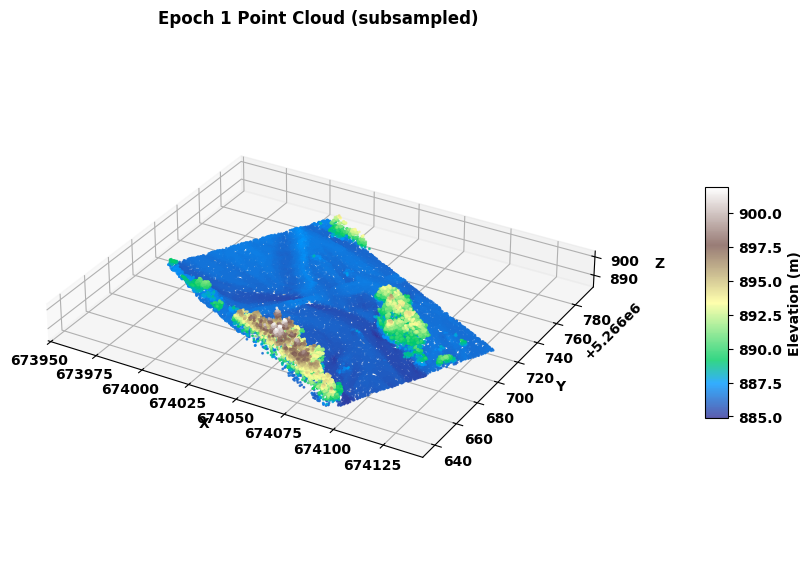

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator 

subset = epoch1.cloud[::100]
x = subset[:, 0]
y = subset[:, 1]
z = subset[:, 2]
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')
scatter = ax.scatter(x, y, z, c=z, cmap='terrain', s=1, alpha=0.8)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Epoch 1 Point Cloud (subsampled)")
ax.set_aspect('equal')
ax.zaxis.set_major_locator(MaxNLocator(nbins=2))
fig.colorbar(scatter, ax=ax, shrink=0.3, aspect=10, label='Elevation (m)', pad=0.15)

plt.show()

## Bi-temporal analysis using M3C2

The analysis of point cloud distances is executed on so-called *core points* ([Lague et al., 2013](#References)). These could be, e.g., one of the input point clouds, a subsampled version thereof, points in an equidistant grid, etc. Here, we choose a subsampling by taking every 50th point of the reference point cloud.

In [4]:
# a more detailed expalnation of m3c2, a graphic abstract of the method
corepoints = epoch1.cloud[::50]

Now we are ready to set up and run the M3C2 algorithm. Let's take a closer look at the parameters:

*   `epochs=(epoch1, epoch2)`: This is a tuple containing the two point clouds (from different times) that we want to compare. `epoch1` is treated as the reference cloud, and `epoch2` as the target cloud.
*   `corepoints=corepoints`: These are the specific points at which the M3C2 distances will be calculated. The algorithm will compute one distance value for each point in this array.
*   `cyl_radius=2.0`: This is the **projection cylinder radius**. For each core point, M3C2 projects the local neighborhood of points from both clouds into a cylinder to calculate the average distance. This radius defines the size of the cylinder.
*   `normal_radii=[0.5, 1.0, 1.5, 2.0]`: This is a list of radii used for calculating the surface normal at each core point. 
This parameter enables the **multi-scale** nature of M3C2. The algorithm calculates a surface normal for each of the provided radii and then evaluates the "planarity" of the surface at each scale. It automatically selects the normal from the radius that corresponds to the flattest local surface (i.e., the most reliable scale for determining the surface orientation).

    *   A **small radius** is good for capturing fine details on a complex surface.
    *   A **large radius** is better for smoothing over noise on a generally flat surface.

By providing a list of radii, you allow the algorithm to adaptively choose the most appropriate scale for each individual core point.

In [5]:
m3c2 = py4dgeo.M3C2(
    epochs=(epoch1, epoch2),
    corepoints=corepoints,
    cyl_radius=2.0,
    normal_radii=[0.5, 1.0, 1.5, 2.0],
)

distances, uncertainties = m3c2.run()

[2026-05-12 17:06:24][INFO] Building KDTree structure with leaf parameter 10
[2026-05-12 17:06:28][INFO] Building KDTree structure with leaf parameter 10


In [6]:
distances

array([-0.02623343,  0.00132395,  0.00197531, ...,  0.05216049,
       -0.17266255, -0.17584255], shape=(65246,))

## Visualization
Now that we have the distances, the best way to interpret them is to visualize them on the point cloud. We will create a 3D scatter plot of our core points, and use the M3C2 distances to color each point.

In [ ]:
import plotly.graph_objects as go
import numpy as np

vmax = 1.8
fig = go.Figure(data=go.Scatter3d(
    x=corepoints[:, 0],
    y=corepoints[:, 1],
    z=corepoints[:, 2],
    mode='markers',
    marker=dict(
        size=2,
        color=distances,
        colorscale='RdBu',
        cmin=-vmax,
        cmax=vmax,
        colorbar=dict(title='M3C2 Distance (m)'),
    ),
    hovertemplate=(
        "X: %{x:.2f}<br>"
        "Y: %{y:.2f}<br>"
        "Z: %{z:.2f}<br>"
        "Distance: %{marker.color:.3f} m<extra></extra>"
    ),
))
fig.update_layout(
    title="M3C2 Distances on Core Points",
    scene=dict(
        xaxis_title="X",
        yaxis_title="Y",
        zaxis_title="Z",
        aspectmode="data",
    ),
    width=800,
    height=700,
)
fig.show()

## Further resources

If you want to explore more features and details of `py4dgeo`, you can visit the following resources:

- [`py4dgeo` M3C2 documentation](https://py4dgeo.readthedocs.io/en/latest/m3c2.html) — Full API reference and parameter descriptions for the M3C2 implementation
- [`py4dgeo` library documentation](https://py4dgeo.readthedocs.io/en/latest/index.html) — Overview of all available change detection methods, including time series analysis
- [`py4dgeo` GitHub repository](https://github.com/3dgeo-heidelberg/py4dgeo) — Source code, issue tracker, and example notebooks


## References
* Lague, D., Brodu, N., & Leroux, J. (2013). Accurate 3D comparison of complex topography with terrestrial laser scanner: Application to the Rangitikei canyon (N-Z). ISPRS Journal of Photogrammetry and Remote Sensing, 82, pp. 10-26. doi: [10.1016/j.isprsjprs.2013.04.009](https://doi.org/10.1016/j.isprsjprs.2013.04.009)."
  